# Enthalpy balance of the control volume, per oscillation

Per-cycle enthalpy bookkeeping for the acoustic expander, using the cycle-extraction and
integration machinery from `V_passive_sweep_energy_balance.ipynb`.

**Quantities tracked for every oscillation cycle:**

- Enthalpy flow **in** through the inlet reed: $\dot H_{in} = \dot m_{in}\, c_p\, T_{in}$, integrated per cycle.
- Enthalpy flow **out** through the outlet reed: $\dot H_{out} = \dot m_{out}\, c_p\, T_{cv}$, integrated per cycle.
- **Total enthalpy of the control volume** (ideal gas): $H_{cv} = M_{cv}\, c_p\, T_{cv}$, cycle-averaged.
- **Average pressure** of the control volume: $\bar P_{cv} = \frac{1}{T}\oint P_{cv}\,dt$.

**Why enthalpy is related to the average pressure.** For an ideal gas, $P V = M R T$, so
$$
H_{cv} = M_{cv} c_p T_{cv} = \frac{c_p}{R}\, P_{cv} V_{cv}
\quad\Longrightarrow\quad
\langle H_{cv}\rangle = \frac{c_p}{R}\,\langle P_{cv} V_{cv}\rangle
\;\approx\; \frac{c_p}{R}\,\bar V_{cv}\,\bar P_{cv},
$$
i.e. the enthalpy content of the CV is *proportional to the average pressure* (times the average
volume), up to the small covariance $\langle P'V'\rangle$ between the pressure and volume oscillations.
The scatter plot at the end tests this proportionality directly against the simulation.

**Cycle detection.** The pressure oscillates fast (~100–135 Hz) and the equilibrium position can
drift, so cycles are found from upward zero crossings of the displacement $x$ centered on a
rolling-median baseline (`upward_zero_crossing_cycles`), not from raw peaks &mdash; the same robust
extractor validated in `V_passive_sweep_energy_balance.ipynb`.


1. Write down the first law of thermodynamics + mass conservation (maybe also $PV^\gamma$, second law)
2. separate $P = P(t) + P_{amp} \exp(i\omega t - i k x) $
3. similarly for $T$, the temperature
4. Justify and Derive the $H = c_p P V$ equation

Include PdV work

In [1]:
import gc
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# Fluid properties
gamma = 1.41
R = 287
cp = 1050
cv = 744

# Pressures (Pa). Match V_passive_sweep_energy_balance.ipynb.
P_in = 6e5
P_out = 5.45e5
P0 = 5.75e5

# Temperatures (K)
T_in = 300
T0 = T_in

# Resonator geometry
A_neck = 2.85e-4
L_neck = 0.15
m_gas = 0.0015
V0_cv = 1e-4
V0_pass_base = 3.93e-4

# Damping from Q = 60
f = 135
omega = 2 * np.pi * f
Q = 60
b_gas = 0.005

# Reed parameters
zeta = 0.6
dP = P_in - P_out
dP_max = dP / (2 * zeta)
m_max = 0.001

# Time horizon / resolution
t_span = (0.0, 0.8)
n_eval = 20_000

# Initial conditions
x0 = 0.0
v0 = 5.0

start_cycle = 1


In [2]:
def reed_flow(dP, m_max_, dP_max_):
    u = dP / dP_max_
    if dP > 0 and dP < dP_max_:
        return m_max_ * (1 - u) * np.sqrt(u)
    elif dP <= 0:
        return -m_max_ * (1 - u) * np.sqrt(abs(u))
    return 0.0


def reed_flow_vec(dP, m_max_, dP_max_):
    dP = np.asarray(dP)
    u = dP / dP_max_
    out = np.zeros_like(dP, dtype=float)

    mask_open = (dP > 0) & (dP < dP_max_)
    mask_reverse = dP <= 0

    out[mask_open] = m_max_ * (1 - u[mask_open]) * np.sqrt(u[mask_open])
    out[mask_reverse] = -m_max_ * (1 - u[mask_reverse]) * np.sqrt(np.abs(u[mask_reverse]))
    return out


def acoustic_expander_ode(t, y, P_in_, P_out_, P0_, T_in_, T0_, gamma_, R_, cp_, cv_,
                          A_neck_, V0_cv_, V0_pass_, m_gas_, b_gas_, m_max_, dP_max_):
    x, v, M_cv, E_cv = y

    V_cv = V0_cv_ + x * A_neck_
    T_cv = E_cv / (cv_ * M_cv) if M_cv > 0 else T0_
    P_cv = M_cv * R_ * T_cv / V_cv

    V_pass = V0_pass_ - x * A_neck_
    P_pass = P0_ * (V0_pass_ / V_pass)**gamma_ if V_pass > 0 else P0_

    m_in = reed_flow(P_in_ - P_cv, m_max_, dP_max_)
    m_out = reed_flow(P_cv - P_out_, m_max_, dP_max_)

    dV_cv_dt = A_neck_ * v
    dM_dt = m_in - m_out
    dE_dt = -P_cv * dV_cv_dt + m_in * cp_ * T_in_ - m_out * cp_ * T_cv

    dx_dt = v
    dv_dt = (P_cv - P_pass) * A_neck_ / m_gas_ - (b_gas_ / m_gas_) * v

    return [dx_dt, dv_dt, dM_dt, dE_dt]


def initial_state_for_parameters(P0_, V0_cv_, R_, T0_, cv_, x0_, v0_):
    M0_cv = P0_ * V0_cv_ / (R_ * T0_)
    E0_cv = cv_ * M0_cv * T0_
    return [x0_, v0_, M0_cv, E0_cv]


def simulate_for_case(V0_cv_value, V0_pass_value, t_span_=None, n_eval_=None):
    ts = t_span if t_span_ is None else t_span_
    ne = n_eval if n_eval_ is None else n_eval_
    t_eval = np.linspace(ts[0], ts[1], ne)
    y0_local = initial_state_for_parameters(P0, V0_cv_value, R, T0, cv, x0, v0)
    ode_args = (P_in, P_out, P0, T_in, T0, gamma, R, cp, cv,
                A_neck, V0_cv_value, V0_pass_value, m_gas, b_gas, m_max, dP_max)
    sol = solve_ivp(acoustic_expander_ode, ts, y0_local, t_eval=t_eval, args=ode_args,
                    method='RK45', rtol=1e-6, atol=1e-8)
    sol.V0_cv = V0_cv_value
    sol.V0_pass = V0_pass_value
    return sol


In [3]:
def solution_quantities(sol):
    t = sol.t
    x = sol.y[0]
    v = sol.y[1]
    M_cv = sol.y[2]
    E_cv = sol.y[3]
    V0_cv_used = getattr(sol, 'V0_cv', V0_cv)

    V_cv = V0_cv_used + x * A_neck
    T_cv = E_cv / (cv * M_cv)
    P_cv = M_cv * R * T_cv / V_cv
    dV_cv_dt = A_neck * v

    return t, x, v, M_cv, E_cv, V_cv, T_cv, P_cv, dV_cv_dt


def cumulative_trapezoid_values(t, y):
    return np.concatenate(([0.0], np.cumsum(0.5 * (y[1:] + y[:-1]) * np.diff(t))))


def integral_between(t, cumulative, t0, t1):
    return np.interp(t1, t, cumulative) - np.interp(t0, t, cumulative)


def rolling_median(y, window=31):
    y = np.asarray(y, dtype=float)
    if y.size == 0:
        return y
    window = int(window)
    if window < 3:
        return y.copy()
    if window % 2 == 0:
        window += 1
    half = window // 2
    out = np.empty_like(y)
    for i in range(y.size):
        lo = max(0, i - half)
        hi = min(y.size, i + half + 1)
        out[i] = np.nanmedian(y[lo:hi])
    return out


def upward_zero_crossing_cycles(t, x, min_period_factor=0.55, max_period_factor=1.55, baseline_periods=2.0):
    # Center on a rolling baseline (~baseline_periods oscillation periods wide) instead of
    # the global median, so crossing detection keeps tracking a slowly drifting equilibrium.
    dt = np.median(np.diff(t))
    window = max(5, int(round(baseline_periods * (1.0 / f) / dt)))
    baseline = rolling_median(x, window=window)
    x_centered = x - baseline
    finite = np.isfinite(x_centered)
    if finite.sum() < 3:
        raise ValueError('Not enough finite displacement samples for cycle detection.')

    idx = np.flatnonzero(
        finite[:-1]
        & finite[1:]
        & (x_centered[:-1] < 0.0)
        & (x_centered[1:] >= 0.0)
    )
    if idx.size < 2:
        raise ValueError('Need at least two upward zero crossings to define cycles.')

    y0 = x_centered[idx]
    y1 = x_centered[idx + 1]
    t0 = t[idx]
    t1 = t[idx + 1]
    denom = y1 - y0
    ok = np.abs(denom) > 0
    crossings = t0[ok] - y0[ok] * (t1[ok] - t0[ok]) / denom[ok]

    periods = np.diff(crossings)
    positive = periods > 0
    if not np.any(positive):
        raise ValueError('No positive cycle periods found from zero crossings.')

    period_ref = np.nanmedian(periods[positive])
    valid = positive & (periods >= min_period_factor * period_ref) & (periods <= max_period_factor * period_ref)
    cycle_numbers = np.arange(1, periods.size + 1)

    return {
        't_start': crossings[:-1][valid],
        't_end': crossings[1:][valid],
        'period': periods[valid],
        'cycle_number': cycle_numbers[valid],
        'period_ref': period_ref,
        'n_rejected': int(np.count_nonzero(~valid)),
        'n_total': int(periods.size),
    }


In [4]:
def enthalpy_per_cycle(sol, start_cycle=1):
    """Per-cycle enthalpy flows, cycle-averaged CV enthalpy, and cycle-averaged pressure.

    Returns arrays aligned by cycle:
      H_in, H_out   -- enthalpy carried in/out by the reed flows over each cycle (J)
      H_avg         -- time-average of the CV's total enthalpy H_cv = M_cv*cp*T_cv over each cycle (J)
      P_avg         -- time-average of P_cv over each cycle (Pa)
      V_avg         -- time-average of V_cv over each cycle (m^3)
      PV_avg_cpR    -- (cp/R) * <P_cv*V_cv> per cycle; identical to H_avg for an ideal gas (consistency check)
    """
    t, x, v, M_cv, E_cv, V_cv, T_cv, P_cv, dV_cv_dt = solution_quantities(sol)

    m_in = reed_flow_vec(P_in - P_cv, m_max, dP_max)
    m_out = reed_flow_vec(P_cv - P_out, m_max, dP_max)
    Hdot_in = m_in * cp * T_in
    Hdot_out = m_out * cp * T_cv
    H_cv = M_cv * cp * T_cv          # total enthalpy of the CV (= (cp/R) * P_cv * V_cv)

    cycles = upward_zero_crossing_cycles(t, x)
    keep = cycles['cycle_number'] >= start_cycle
    if not np.any(keep):
        raise ValueError(f'No valid cycles found at or after cycle {start_cycle}.')
    cycle_number = cycles['cycle_number'][keep]
    t_start = cycles['t_start'][keep]
    t_end = cycles['t_end'][keep]
    period = cycles['period'][keep]

    cum_Hin = cumulative_trapezoid_values(t, Hdot_in)
    cum_Hout = cumulative_trapezoid_values(t, Hdot_out)
    cum_H = cumulative_trapezoid_values(t, H_cv)
    cum_P = cumulative_trapezoid_values(t, P_cv)
    cum_V = cumulative_trapezoid_values(t, V_cv)
    cum_PV = cumulative_trapezoid_values(t, P_cv * V_cv)

    H_in = np.array([integral_between(t, cum_Hin, a, b) for a, b in zip(t_start, t_end)])
    H_out = np.array([integral_between(t, cum_Hout, a, b) for a, b in zip(t_start, t_end)])
    H_avg = np.array([integral_between(t, cum_H, a, b) for a, b in zip(t_start, t_end)]) / period
    P_avg = np.array([integral_between(t, cum_P, a, b) for a, b in zip(t_start, t_end)]) / period
    V_avg = np.array([integral_between(t, cum_V, a, b) for a, b in zip(t_start, t_end)]) / period
    PV_avg_cpR = (cp / R) * np.array([integral_between(t, cum_PV, a, b)
                                      for a, b in zip(t_start, t_end)]) / period

    return {
        'cycle_number': cycle_number,
        'period': period,
        'H_in': H_in,
        'H_out': H_out,
        'H_avg': H_avg,
        'P_avg': P_avg,
        'V_avg': V_avg,
        'PV_avg_cpR': PV_avg_cpR,
    }


In [5]:
def plot_enthalpy_analysis(sol, start_cycle=1):
    """Three stacked panels sharing the cycle axis (no dual axes):
    (1) enthalpy in & out per cycle, (2) cycle-averaged total CV enthalpy,
    (3) cycle-averaged CV pressure. Panels 2 and 3 should track each other,
    since H_cv = (cp/R) P_cv V_cv."""
    r = enthalpy_per_cycle(sol, start_cycle=start_cycle)
    n = r['cycle_number']
    V0_cv_used = getattr(sol, 'V0_cv', V0_cv)
    V0_pass_used = getattr(sol, 'V0_pass', np.nan)
    label = f'V0_cv={V0_cv_used * 1e4:.2f}, V0_pass={V0_pass_used * 1e4:.2f} (x1e-4 m^3)'

    fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(8.4, 8.6), sharex=True)

    ax1.plot(n, r['H_in'] * 1e3, lw=1.8, color='tab:blue', label='enthalpy in per cycle')
    ax1.plot(n, r['H_out'] * 1e3, lw=1.8, color='tab:orange', label='enthalpy out per cycle')
    ax1.fill_between(n, r['H_in'] * 1e3, r['H_out'] * 1e3,
                     where=r['H_in'] >= r['H_out'], color='tab:green', alpha=0.18,
                     interpolate=True, label='net in > 0')
    ax1.fill_between(n, r['H_in'] * 1e3, r['H_out'] * 1e3,
                     where=r['H_in'] < r['H_out'], color='tab:red', alpha=0.18, interpolate=True)
    ax1.set_ylabel('enthalpy per cycle (mJ)')
    ax1.set_title('Enthalpy carried by the reed flows  |  ' + label)
    ax1.legend(fontsize=8, loc='best')
    ax1.grid(alpha=0.25)

    ax2.plot(n, r['H_avg'], lw=1.8, color='tab:purple')
    ax2.set_ylabel(r'$\langle H_{cv}\rangle$ (J)')
    ax2.set_title(r'Total enthalpy of the CV, cycle-averaged:  $H_{cv}=M_{cv}c_pT_{cv}=\frac{c_p}{R}P_{cv}V_{cv}$')
    ax2.grid(alpha=0.25)

    ax3.plot(n, r['P_avg'] / 1e5, lw=1.8, color='tab:green')
    ax3.set_ylabel(r'$\langle P_{cv}\rangle$ (bar)')
    ax3.set_xlabel('cycle number')
    ax3.set_title('Average CV pressure per cycle (same shape as the enthalpy above)')
    ax3.grid(alpha=0.25)
    ax3.set_xlim(n[0], n[-1])

    plt.tight_layout()
    plt.show()
    return r


def plot_enthalpy_vs_pressure(result, sol):
    """The quantitative H-P relation: cycle-averaged enthalpy vs cycle-averaged pressure,
    against the ideal-gas prediction H = (cp/R) * V_avg * P_avg computed per cycle."""
    n = result['cycle_number']
    P_avg = result['P_avg']
    H_avg = result['H_avg']
    H_pred = (cp / R) * result['V_avg'] * P_avg     # pressure-only prediction (ignores <P'V'> covariance)
    V0_cv_used = getattr(sol, 'V0_cv', V0_cv)

    # exact check: <H> must equal (cp/R)<PV>
    rel_err = np.nanmax(np.abs(result['PV_avg_cpR'] - H_avg) / np.abs(H_avg))

    fig, ax = plt.subplots(figsize=(6.6, 5.2))
    sc = ax.scatter(P_avg / 1e5, H_avg, c=n, cmap='viridis', s=14, label='cycles')
    order = np.argsort(P_avg)
    ax.plot(P_avg[order] / 1e5, H_pred[order], 'r-', lw=1.8,
            label=r'$\frac{c_p}{R}\,\bar V_{cv}\,\bar P_{cv}$ (per-cycle prediction)')
    ax.set_xlabel(r'$\langle P_{cv}\rangle$ (bar)')
    ax.set_ylabel(r'$\langle H_{cv}\rangle$ (J)')
    ax.set_title('Enthalpy content vs average pressure\n'
                 rf'exact identity $\langle H\rangle=\frac{{c_p}}{{R}}\langle PV\rangle$ holds to '
                 rf'{rel_err:.1e} relative error')
    cb = plt.colorbar(sc)
    cb.set_label('cycle number')
    ax.legend(fontsize=9, loc='best')
    ax.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()


## Run: growing case and decaying case

Same two reference cases used throughout `V_passive_sweep_energy_balance.ipynb`:
a growing/self-sustaining case ($V_{0,cv}=1.0\times10^{-4}$) and a decaying one
($V_{0,cv}=3.67\times10^{-4}$), both at $V_{0,\text{pass}}=2.0\times10^{-4}$ m³.


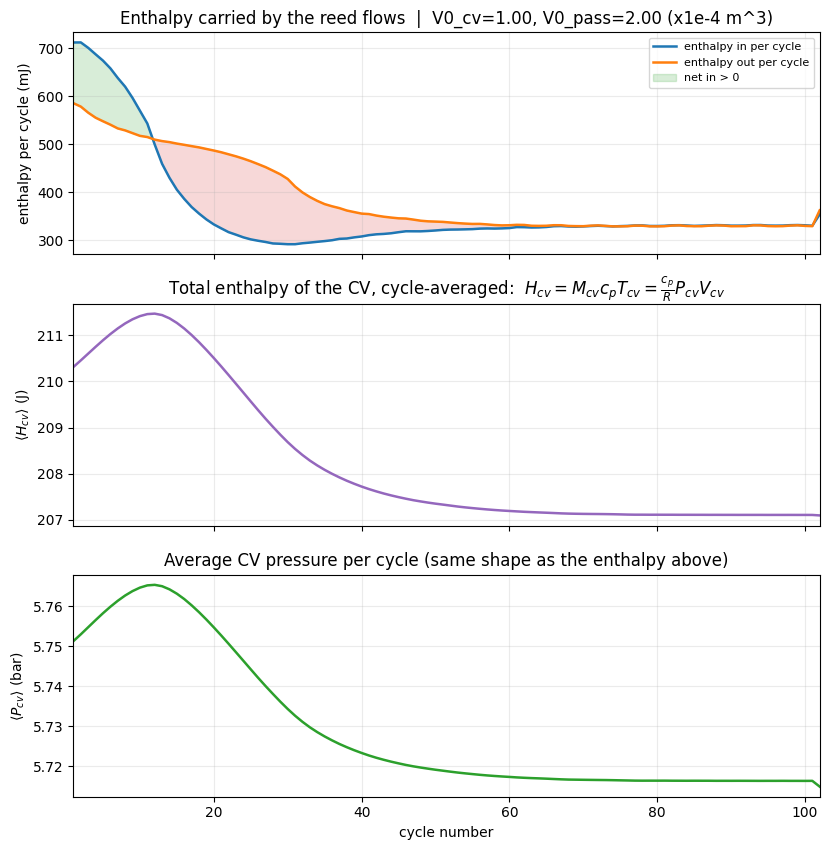

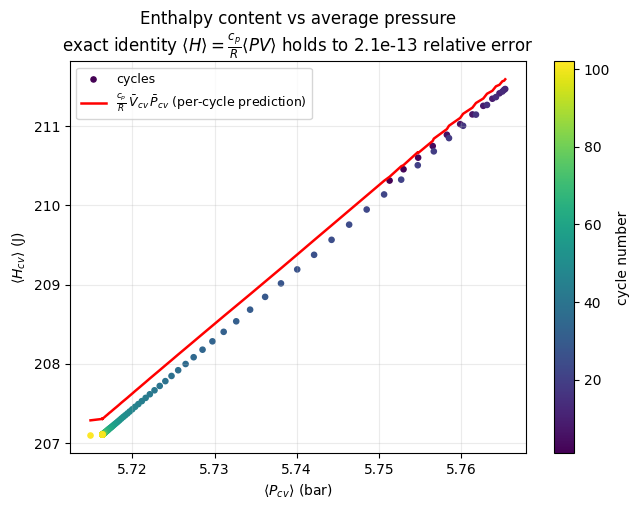

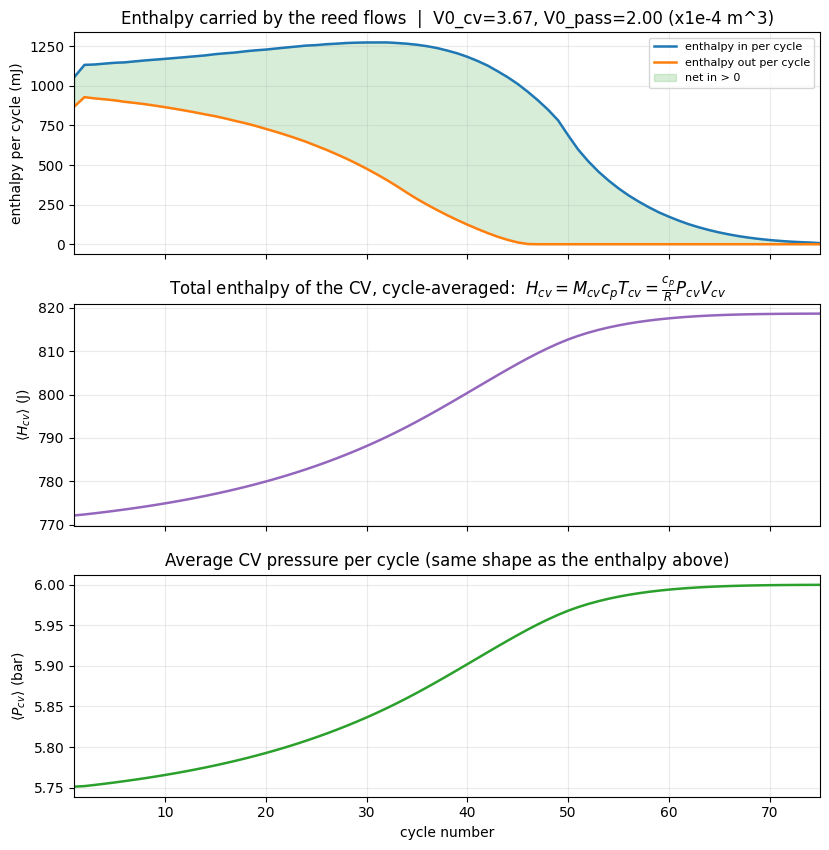

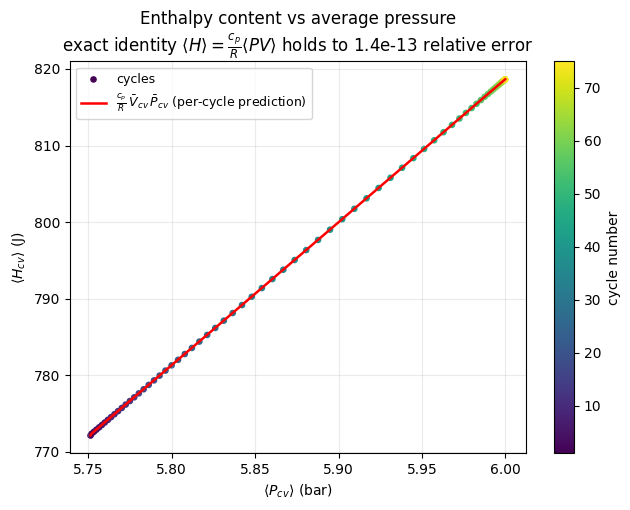

In [6]:
for V0_cv_case in (1.0e-4, 3.67e-4):
    sol_case = simulate_for_case(V0_cv_case, 2.0e-4)
    result_case = plot_enthalpy_analysis(sol_case, start_cycle=start_cycle)
    plot_enthalpy_vs_pressure(result_case, sol_case)
    del sol_case, result_case
    gc.collect()
